# RIASEC27 — Công đoạn 03: Phân tích khám phá dữ liệu
## 1. Mục tiêu và nguyên tắc
Tìm hiểu X27, sáu nhóm RIASEC, sáu mức sở thích Q5, tương quan và phản hồi ít biến thiên **chỉ trên Train**. Không chuẩn hóa bằng scaler, chọn đặc trưng, huấn luyện, đánh giá mô hình hoặc ra quyết định dựa Test. Q5 là sáu đầu ra thứ bậc, không phải nhãn 33 ngành đại học.

Likert là thang thứ bậc. Mean, SD và variance trên mã số chỉ mô tả gần đúng, không xác nhận khoảng cách tâm lý giữa các mức bằng nhau. Spearman mô tả quan hệ đơn điệu, không chứng minh quan hệ nhân quả hoặc giá trị tư vấn nghề nghiệp.

## 2. Tái lập làm sạch và phép chia
Nguồn duy nhất `dataLabanAI.xlsx`. Code kiểm tra của Notebook 01/02 được nhúng trực tiếp: xác minh SHA-256, cấu trúc/codebook, ghép SOURCE_ROW một-một, giữ 4.910 dòng và chuyển int64 bảo toàn giá trị. Không dùng file dữ liệu trung gian hoặc biến kernel cũ.

Các kiểm tra thiếu/kiểu/miền ở phần tái lập chỉ xác minh đầu vào. Không tính thống kê EDA trên toàn tập/Test. Chia một lần GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42); group từ factorize MultiIndex đủ X27, sort=False. So sánh chữ ký index với Notebook 02, kiểm tra kích thước/group/tính tách biệt; sau đó bỏ các tham chiếu chứa Test trước EDA.


In [1]:
from pathlib import Path
import sys,hashlib
import pandas as pd
import numpy as np
from IPython.display import display
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
workbook_path = ROOT/'dataLabanAI.xlsx'
sha_before = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
sha_notebook00 = 'c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
assert sha_before == sha_notebook00, 'Workbook khác phiên bản Notebook 00; cần audit lại trước xử lý.'
excel = pd.ExcelFile(workbook_path)
assert excel.sheet_names == ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
raw_riasec = pd.read_excel(excel,sheet_name='RIASEC_27')
raw_q5 = pd.read_excel(excel,sheet_name='SO_THICH_6')
raw_codebook = pd.read_excel(excel,sheet_name='CODEBOOK_33')
# Bản sao gốc dùng đối chiếu, không thay đổi các DataFrame này.
original_riasec = raw_riasec.copy(deep=True)
original_q5 = raw_q5.copy(deep=True)
original_codebook = raw_codebook.copy(deep=True)
print('Python:',sys.version,'; Interpreter:',sys.executable)
print('SHA-256:',sha_before)
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]}
    for name,frame in [('RIASEC_27',raw_riasec),('SO_THICH_6',raw_q5),('CODEBOOK_33',raw_codebook)]]))


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
         Sheet  Số dòng  Số cột
0    RIASEC_27     4910      28
1   SO_THICH_6     4910       7
2  CODEBOOK_33       33       5


In [2]:
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
survey_columns = question_columns+q5_columns
assert raw_riasec.shape == (4910,28) and raw_q5.shape == (4910,7)
assert list(raw_riasec.columns) == ['SOURCE_ROW']+question_columns
assert list(raw_q5.columns) == ['SOURCE_ROW']+q5_columns
assert raw_codebook.MA_COT.is_unique and raw_codebook.MA_COT.tolist() == survey_columns
assert raw_codebook.iloc[:27]['LOAI'].eq('RIASEC rút gọn').all()
assert raw_codebook.iloc[27:]['LOAI'].eq('Mức ưa thích nhóm nghề').all()
assert raw_codebook.iloc[:27]['THANG_DIEM_GOC'].nunique()==1
assert raw_codebook.iloc[27:]['THANG_DIEM_GOC'].nunique()==1
for frame in [raw_riasec,raw_q5]:
    assert frame.SOURCE_ROW.notna().all() and frame.SOURCE_ROW.is_unique
    assert pd.api.types.is_integer_dtype(frame.SOURCE_ROW)
assert set(raw_riasec.SOURCE_ROW) == set(raw_q5.SOURCE_ROW)
merged = raw_riasec.merge(raw_q5,on='SOURCE_ROW',how='outer',validate='one_to_one',indicator=True,sort=False)
display(merged['_merge'].value_counts().rename('Số dòng sau ghép').to_frame())
assert len(merged) == len(raw_riasec) == len(raw_q5) == 4910
assert merged['_merge'].eq('both').all()
merged = merged.drop(columns='_merge').set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW].reset_index()
assert merged.SOURCE_ROW.equals(raw_riasec.SOURCE_ROW)
assert merged[question_columns].equals(raw_riasec[question_columns])
assert merged[q5_columns].equals(raw_q5.set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW,q5_columns].reset_index(drop=True))
df_original = merged.copy(deep=True)
raw_survey = df_original[survey_columns].copy()
print('PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.')


PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.


            Số dòng sau ghép
_merge                      
both                    4910
left_only                  0
right_only                 0

In [3]:
type_rows = []
for col in survey_columns:
    values = raw_survey[col]
    numeric = pd.to_numeric(values,errors='coerce')
    is_numeric_cell = values.map(lambda value:isinstance(value,(int,float,np.integer,np.floating)) and not isinstance(value,(bool,np.bool_)))
    valid = is_numeric_cell & numeric.isin([1,2,3,4,5])
    type_rows.append({'Cột':col,'dtype gốc':str(values.dtype),'Thiếu':int(values.isna().sum()),
        'Sai kiểu hoặc ngoài miền':int((values.notna() & ~valid).sum())})
type_check = pd.DataFrame(type_rows).set_index('Cột')
display(type_check)
if type_check['Thiếu'].sum() or type_check['Sai kiểu hoặc ngoài miền'].sum():
    raise RuntimeError('Có giá trị sai/thiếu; dừng để quyết định xử lý, không tự sửa.')
survey_int = raw_survey.astype('int64')
assert np.array_equal(survey_int.to_numpy(),raw_survey.to_numpy())
assert survey_int.isin(range(1,6)).all().all()
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in survey_int.dtypes)
answers27 = survey_int[question_columns].copy()
preferences6 = survey_int[q5_columns].copy()
print('PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.')


PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.


          dtype gốc  Thiếu  Sai kiểu hoặc ngoài miền
Cột                                                 
R1            int64      0                         0
I1            int64      0                         0
A1            int64      0                         0
R2            int64      0                         0
I2            int64      0                         0
A2            int64      0                         0
S1            int64      0                         0
S2            int64      0                         0
R3            int64      0                         0
A3            int64      0                         0
S3            int64      0                         0
E1            int64      0                         0
R4            int64      0                         0
S4            int64      0                         0
E2            int64      0                         0
R5            int64      0                         0
I3            int64      0                    

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import sklearn
X = answers27.copy()
y = preferences6.copy()
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X),sort=False)[0],index=X.index,name='group_X27')
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train_pos,test_pos = next(splitter.split(X,groups=groups))
X_train,X_test = X.iloc[train_pos].copy(),X.iloc[test_pos].copy()
y_train,y_test = y.iloc[train_pos].copy(),y.iloc[test_pos].copy()
groups_train,groups_test = groups.iloc[train_pos].copy(),groups.iloc[test_pos].copy()
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert groups_train.nunique()==3568 and groups_test.nunique()==892
assert X.index.is_unique and X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==4910
assert set(X_train.index)|set(X_test.index)==set(X.index)
assert set(groups_train).isdisjoint(groups_test)
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test.itertuples(index=False,name=None))
assert list(X_train.columns)==list(X_test.columns)==question_columns
assert list(y_train.columns)==list(y_test.columns)==q5_columns
assert y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index)
assert y_train.equals(y.loc[X_train.index]) and y_test.equals(y.loc[X_test.index])
train_index_sha256=hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()
test_index_sha256=hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()
assert train_index_sha256=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
assert test_index_sha256=='92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b'
print('PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.')
print('SHA index Train/Test:',train_index_sha256,test_index_sha256)
print('pandas/numpy/sklearn:',pd.__version__,np.__version__,sklearn.__version__)
# Giữ codebook và đường dẫn/hash; bỏ các DataFrame có phản hồi Test/toàn tập.
del X_test,y_test,groups_test,X,y,groups,train_pos,test_pos
# Các bản sao toàn tập từ bước đọc/làm sạch cũng không dùng cho EDA.
del raw_riasec,raw_q5,original_riasec,original_q5,merged,df_original,raw_survey,survey_int,answers27,preferences6

# Bỏ cả alias còn lại của các vòng kiểm tra kiểu/khóa.
del frame,values,numeric,is_numeric_cell,valid


PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.
SHA index Train/Test: 471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d 92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b
pandas/numpy/sklearn: 3.0.6 2.5.3 1.9.1


## 3–4. Tổng quan Train và phân bố 27 câu
Ngưỡng mô tả định trước: SD <0,5 là biến thiên rất thấp; một mức ≥80% là tập trung mạnh. Các ngưỡng này không là quy tắc tâm trắc hoặc tiêu chí tự loại câu. Bảng báo đủ tần suất/tỷ lệ 1–5, mean, median, SD mẫu ddof=1 và variance ddof=0.


Train: 3963 dòng; 27 câu; 6 Q5; 3568 group.
Câu SD <0,5: [] ; câu một mức >=80%: []
SD min/max: 1.0146299428845489 1.2210328656095728
Tỷ lệ mức phổ biến cao nhất: 36.89124400706535


    Mức 1  Mức 2  Mức 3  Mức 4  Mức 5
R1    778   1157   1311    493    224
I1    707    948   1439    642    227
A1    566    974   1396    714    313
R2    650   1110   1404    629    170
I2    679   1185   1364    512    223
A2    684   1225   1305    533    216
S1    631   1063   1327    649    293
S2    571    982   1432    675    303
R3    810   1302   1159    481    211
A3    559    805   1241    855    503
S3    693   1096   1332    559    283
E1    693   1128   1278    631    233
R4    747   1324   1291    448    153
S4    422    547   1400   1077    517
E2    522    845   1333    850    413
R5    960   1458   1089    330    126
I3    686    999   1275    686    317
A4    779   1078   1223    576    307
E3    499    789   1431    813    431
I4    591   1065   1308    676    323
A5    792   1289   1240    429    213
E4    649   1152   1408    571    183
C1    643   1014   1462    614    230
E5    654   1180   1350    583    196
C2    734   1323   1350    428    128
C3    856   

      mean  median     std  min  max  variance ddof=0  Tỷ lệ mức phổ biến (%)    Mức 1    Mức 2    Mức 3    Mức 4    Mức 5
R1  2.5529     3.0  1.1082  1.0  5.0           1.2278                 33.0810  19.6316  29.1951  33.0810  12.4401   5.6523
I1  2.6805     3.0  1.1145  1.0  5.0           1.2419                 36.3109  17.8400  23.9213  36.3109  16.1998   5.7280
A1  2.8067     3.0  1.1296  1.0  5.0           1.2758                 35.2258  14.2821  24.5773  35.2258  18.0167   7.8981
R2  2.6364     3.0  1.0651  1.0  5.0           1.1343                 35.4277  16.4017  28.0091  35.4277  15.8718   4.2897
I2  2.6001     3.0  1.0858  1.0  5.0           1.1787                 34.4184  17.1335  29.9016  34.4184  12.9195   5.6271
A2  2.5892     3.0  1.0879  1.0  5.0           1.1832                 32.9296  17.2597  30.9109  32.9296  13.4494   5.4504
S1  2.7250     3.0  1.1355  1.0  5.0           1.2890                 33.4847  15.9223  26.8231  33.4847  16.3765   7.3934
S2  2.7873     3

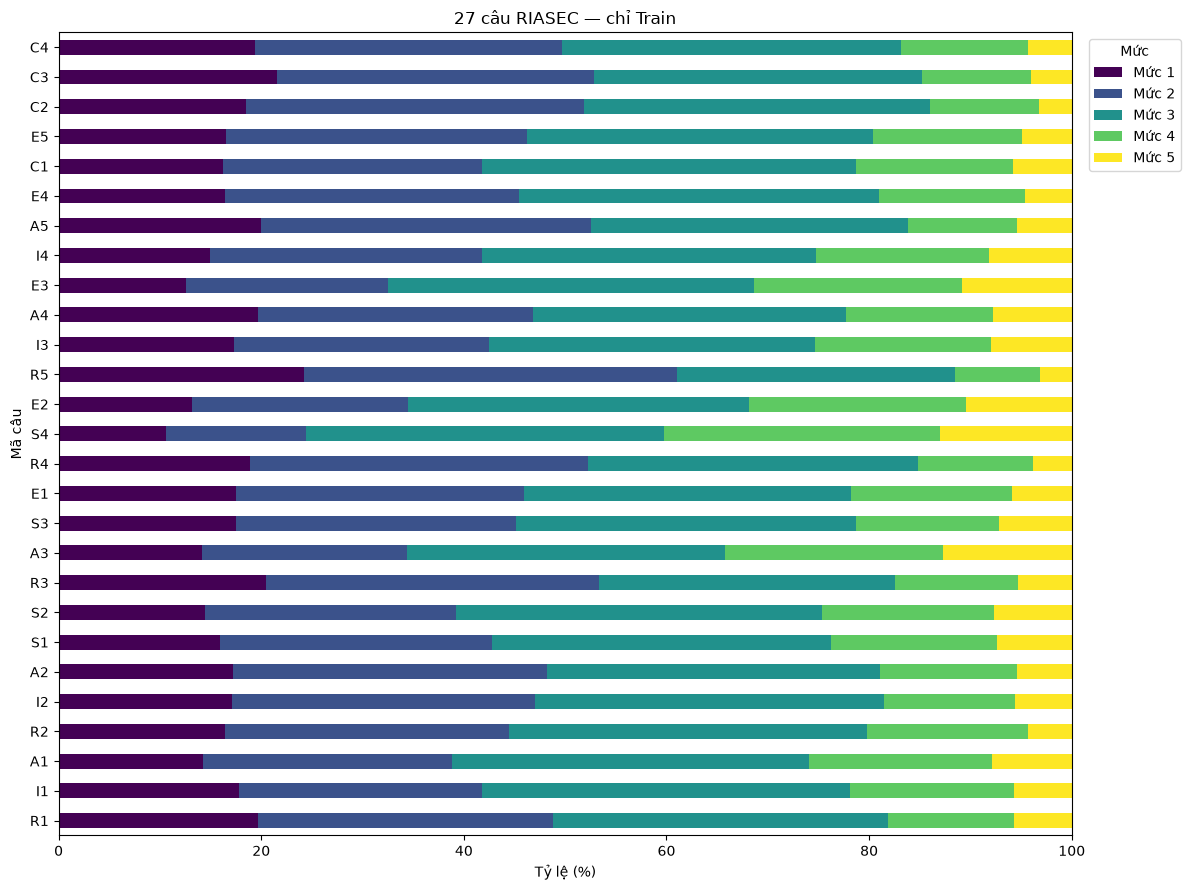

In [5]:
assert X_train.shape==(3963,27) and y_train.shape==(3963,6)
assert X_train.index.equals(y_train.index) and X_train.index.equals(groups_train.index)
assert X_train.notna().all().all() and y_train.notna().all().all()
assert X_train.isin(range(1,6)).all().all() and y_train.isin(range(1,6)).all().all()
assert not set(q5_columns+['SOURCE_ROW']).intersection(X_train.columns)
print('Train:',len(X_train),'dòng;',X_train.shape[1],'câu;',y_train.shape[1],'Q5;',groups_train.nunique(),'group.')
item_counts=pd.DataFrame({col:X_train[col].value_counts().reindex(range(1,6),fill_value=0) for col in question_columns}).T
item_counts.columns=[f'Mức {level}' for level in range(1,6)]
item_rates=item_counts/len(X_train)*100
item_stats=X_train.agg(['mean','median','std','min','max']).T
item_stats['variance ddof=0']=X_train.var(ddof=0)
item_stats['Tỷ lệ mức phổ biến (%)']=item_rates.max(axis=1)
low_items=item_stats.index[item_stats['std']<.5].tolist()
dominant_items=item_stats.index[item_stats['Tỷ lệ mức phổ biến (%)']>=80].tolist()
display(item_counts)
display(item_stats.join(item_rates).round(4))
print('Câu SD <0,5:',low_items,'; câu một mức >=80%:',dominant_items)
print('SD min/max:',item_stats['std'].min(),item_stats['std'].max())
print('Tỷ lệ mức phổ biến cao nhất:',item_stats['Tỷ lệ mức phổ biến (%)'].max())
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(12,9))
item_rates.plot.barh(stacked=True,ax=ax,colormap='viridis')
ax.set(title='27 câu RIASEC — chỉ Train',xlabel='Tỷ lệ (%)',ylabel='Mã câu',xlim=(0,100))
ax.legend(title='Mức',bbox_to_anchor=(1.01,1));plt.tight_layout();plt.show()


Nhận xét: bảng phân bố cho phép đối chiếu khả năng phân biệt quan sát được giữa các câu; SD thấp không tự chứng minh câu hỏi kém giá trị. Các câu vẫn được giữ đủ, đúng thứ tự. Không suy luận sự khác biệt có ý nghĩa thống kê từ biểu đồ đơn thuần.

## 5. Sáu nhóm RIASEC
**Điểm trung bình nhóm RIASEC ở Notebook 03 chỉ là phép tổng hợp mô tả được đề xuất, chưa được xác nhận là quy tắc chấm điểm chính thức của nghiên cứu gốc.**

R/A/E có 5 câu, I/S/C có 4 câu. Không so sánh tổng thô. Dùng histogram chung tám khoảng từ 1 đến 5 để mô tả chồng lấn: overlap = tổng min(tỷ lệ bin của hai nhóm), trong [0,1]. Đây là hệ số mô tả phụ thuộc cách chia bin và độ rời rạc khác nhau của mean 4/5 câu, không là xác thực các nhóm tương đương hoặc độc lập. Sáu điểm của cùng một người là các phép đo ghép cặp.


Overlap histogram (0–1), cùng bins:


   Số câu    mean     std  min   25%   50%   75%  max
R       5  2.4907  0.8514  1.0  2.00  2.40  3.00  5.0
I       4  2.6955  0.8412  1.0  2.00  2.75  3.25  5.0
A       5  2.7012  0.8454  1.0  2.00  2.80  3.20  5.0
S       4  2.8379  0.8425  1.0  2.25  3.00  3.25  5.0
E       5  2.7594  0.8545  1.0  2.20  2.80  3.20  5.0
C       4  2.5308  0.8890  1.0  2.00  2.50  3.00  5.0

        R       I       A       S       E       C
R  1.0000  0.8239  0.8774  0.7474  0.8430  0.9243
I  0.8239  1.0000  0.9177  0.9193  0.9061  0.8854
A  0.8774  0.9177  1.0000  0.8700  0.9548  0.9417
S  0.7474  0.9193  0.8700  1.0000  0.8890  0.8231
E  0.8430  0.9061  0.9548  0.8890  1.0000  0.9187
C  0.9243  0.8854  0.9417  0.8231  0.9187  1.0000

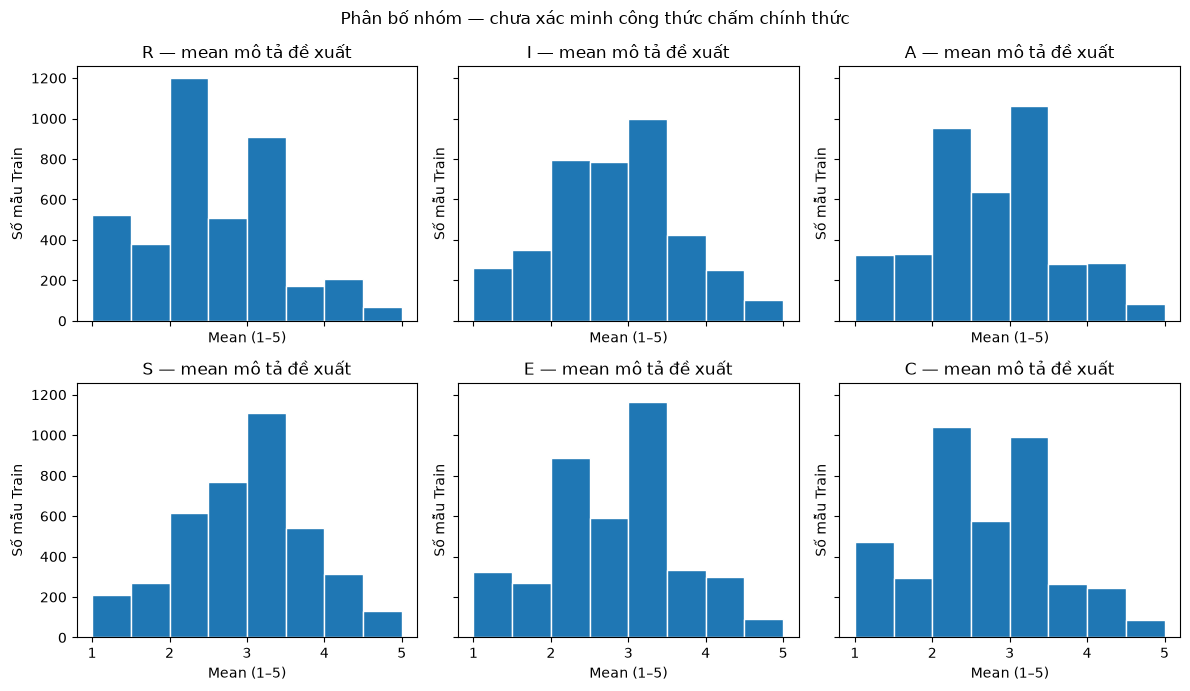

In [6]:
group_questions={key:[col for col in question_columns if col.startswith(key)] for key in ['R','I','A','S','E','C']}
assert {key:len(cols) for key,cols in group_questions.items()}=={'R':5,'I':4,'A':5,'S':4,'E':5,'C':4}
group_means=pd.DataFrame({key:X_train[cols].mean(axis=1) for key,cols in group_questions.items()})
group_stats=group_means.describe().T[['mean','std','min','25%','50%','75%','max']]
group_stats.insert(0,'Số câu',[len(group_questions[key]) for key in group_stats.index])
display(group_stats.round(4))
bins=np.linspace(1,5,9)
group_hist={key:np.histogram(group_means[key],bins=bins)[0]/len(X_train) for key in group_questions}
overlap=pd.DataFrame([[np.minimum(group_hist[a],group_hist[b]).sum() for b in group_questions] for a in group_questions],index=group_questions,columns=group_questions)
print('Overlap histogram (0–1), cùng bins:')
display(overlap.round(4))
fig,axes=plt.subplots(2,3,figsize=(12,7),sharex=True,sharey=True)
for ax,key in zip(axes.flat,group_questions):
    ax.hist(group_means[key],bins=bins,edgecolor='white')
    ax.set(title=key+' — mean mô tả đề xuất',xlabel='Mean (1–5)',ylabel='Số mẫu Train')
fig.suptitle('Phân bố nhóm — chưa xác minh công thức chấm chính thức')
plt.tight_layout();plt.show()


Nhận xét: so sánh mean/median/IQR cùng overlap histogram để mô tả mức tương tự/khác nhau. Các phân bố chồng lấn không có nghĩa sáu nhóm đo cùng một cấu trúc; khác mean không chứng minh khác biệt tâm lý có ý nghĩa. Không chuyển nhóm cao nhất thành nhãn hoặc phần trăm phù hợp nghề.

Overlap histogram thực tế ngoài đường chéo từ 0,7474 (R–S) đến 0,9548 (A–E), cho thấy chồng lấn đáng kể theo tám bins đã chọn. S có mean 2,8379 và R có mean 2,4907; không đồng nhất hóa các nhóm hoặc kết luận tư vấn từ thứ hạng mean.

## 6. Sáu biến Q5 trên y_train
Mỗi biến là mức thích 1–5 riêng biệt. Báo mọi mức đồng hạng phổ biến/ít phổ biến khi có; không dùng argmax theo hàng để tạo nhãn nhóm nghề. Tỷ số max/min số mẫu chỉ mô tả mất cân bằng.

Số/tỷ lệ mẫu có nhiều Q5 đồng hạng cao nhất: 2173 54.83219782992682


           Mức 1 (n)  Mức 2 (n)  Mức 3 (n)  Mức 4 (n)  Mức 5 (n)
Q5_LikeRe       1092        963       1103        427        378
Q5_LikeIn        873        847       1079        637        527
Q5_LikeAr        747        734       1068        677        737
Q5_LikeSo        735        829       1179        676        544
Q5_LikeEn        748        794       1134        737        550
Q5_LikeCo        884        877       1089        658        455

           Mức 1 (%)  Mức 2 (%)  Mức 3 (%)  Mức 4 (%)  Mức 5 (%)
Q5_LikeRe    27.5549    24.2998    27.8325    10.7747     9.5382
Q5_LikeIn    22.0288    21.3727    27.2268    16.0737    13.2980
Q5_LikeAr    18.8494    18.5213    26.9493    17.0830    18.5970
Q5_LikeSo    18.5466    20.9185    29.7502    17.0578    13.7270
Q5_LikeEn    18.8746    20.0353    28.6147    18.5970    13.8784
Q5_LikeCo    22.3063    22.1297    27.4792    16.6036    11.4812

             mean  median     std  min  max Mức phổ biến nhất Mức ít phổ biến nhất  Max/min số mẫu  Thiếu mức
Q5_LikeRe  2.5044     2.0  1.2607  1.0  5.0                 3                    5          2.9180          0
Q5_LikeIn  2.7724     3.0  1.3176  1.0  5.0                 3                    5          2.0474          0
Q5_LikeAr  2.9806     3.0  1.3616  1.0  5.0                 3                    4          1.5775          0
Q5_LikeSo  2.8650     3.0  1.2857  1.0  5.0                 3                    5          2.1673          0
Q5_LikeEn  2.8857     3.0  1.2976  1.0  5.0                 3                    5          2.0618          0
Q5_LikeCo  2.7282     3.0  1.2905  1.0  5.0                 3                    5          2.3934          0

   Số mẫu  Tỷ lệ (%)
1    1790    45.1678
2     875    22.0792
3     420    10.5980
4     178     4.4915
5     101     2.5486
6     599    15.1148

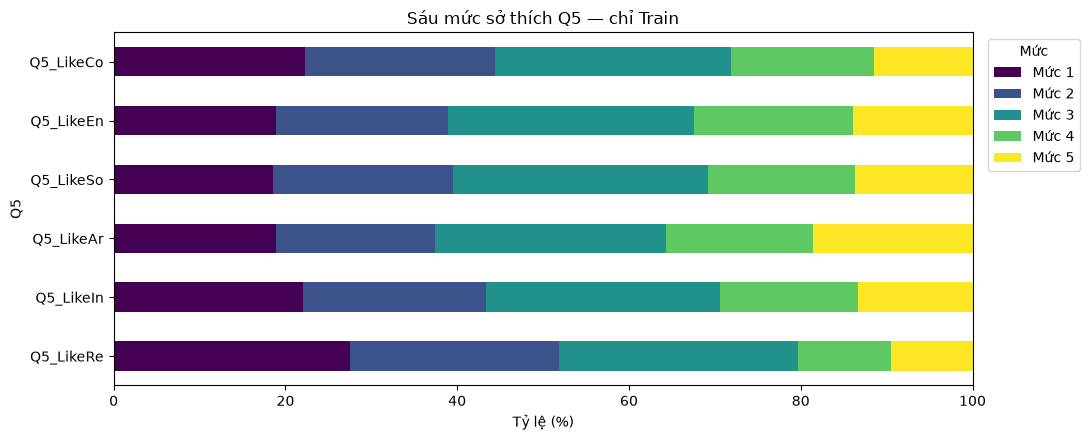

In [7]:
q5_counts=pd.DataFrame({col:y_train[col].value_counts().reindex(range(1,6),fill_value=0) for col in q5_columns}).T
q5_rates=q5_counts/len(y_train)*100
q5_stats=y_train.agg(['mean','median','std','min','max']).T
q5_stats['Mức phổ biến nhất']=[', '.join(map(str,row.index[row.eq(row.max())])) for _,row in q5_counts.iterrows()]
q5_stats['Mức ít phổ biến nhất']=[', '.join(map(str,row.index[row.eq(row.min())])) for _,row in q5_counts.iterrows()]
q5_stats['Max/min số mẫu']=q5_counts.max(axis=1)/q5_counts.min(axis=1).replace(0,np.nan)
q5_stats['Thiếu mức']=q5_counts.eq(0).sum(axis=1)
display(q5_counts.rename(columns=lambda level:f'Mức {level} (n)'))
display(q5_rates.rename(columns=lambda level:f'Mức {level} (%)').round(4))
display(q5_stats.round(4))
top_ties=y_train.eq(y_train.max(axis=1),axis=0).sum(axis=1)
tie_distribution=top_ties.value_counts().reindex(range(1,7),fill_value=0).sort_index().rename('Số mẫu').to_frame()
tie_distribution['Tỷ lệ (%)']=tie_distribution['Số mẫu']/len(y_train)*100
display(tie_distribution.round(4))
print('Số/tỷ lệ mẫu có nhiều Q5 đồng hạng cao nhất:',int(top_ties.gt(1).sum()),top_ties.gt(1).mean()*100)
fig,ax=plt.subplots(figsize=(11,4.5))
q5_rates.rename(columns=lambda level:f'Mức {level}').plot.barh(stacked=True,ax=ax,colormap='viridis')
ax.set(title='Sáu mức sở thích Q5 — chỉ Train',xlabel='Tỷ lệ (%)',ylabel='Q5',xlim=(0,100))
ax.legend(title='Mức',bbox_to_anchor=(1.01,1));plt.tight_layout();plt.show()


Nhận xét: mức phổ biến và tỷ lệ max/min cần đọc cùng support; dữ liệu không mặc nhiên cân bằng giữa năm mức. Đồng hạng là kết quả hợp lệ của sáu câu hỏi riêng, chưa có quy tắc khoa học để chọn một nhãn duy nhất. Giữ mọi dòng, không dùng Q5 làm tiêu chí lọc.

## 7. Tương quan Spearman — chỉ Train
Quy ước mô tả trước khi tính: |rho| ≥0,8 là cao; ≥0,9 là rất cao; |rho| ≤0,1 là liên hệ đơn điệu nhỏ. Không xem đây là kiểm định ý nghĩa thống kê, nhân quả hoặc quy tắc loại biến. Thống kê nhiều cặp trên cùng dữ liệu có tính khám phá; vector lặp và xu hướng chọn cùng mức có thể góp phần tạo liên hệ chung.

A: X27–X27; B: sáu mean nhóm; C/D: sáu mean nhóm với sáu Q5. In nội dung codebook của các cặp X mạnh nhất để không nhận xét chỉ theo mã.


Ma trận X27:
Top 10 cặp X27:
Cặp |rho| >=0,8:
Số cặp cao/rất cao/liên hệ nhỏ: 0 0 0
C3 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an auditor/auditing expert]
C4 Which of the following activities did you enjoy doing when you were in lower secondary school? [I like managing banking data and transactions]
R3 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an electronics engineer/electronics expert]
R5 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become a mechanic/mechanical expert]
C2 Which of the following activities did you enjoy doing when you were in lower secondary school? [I like organizing documents and providing administrative support]
C3 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an auditor/auditing expert]
Spearman sá

       R1     I1     A1     R2     I2     A2     S1     S2     R3     A3     S3     E1     R4     S4     E2     R5     I3     A4     E3     I4     A5     E4     C1     E5     C2     C3     C4
R1  1.000  0.377  0.191  0.520  0.297  0.234  0.181  0.247  0.617  0.197  0.351  0.318  0.472  0.227  0.262  0.554  0.384  0.123  0.270  0.253  0.209  0.309  0.270  0.238  0.333  0.326  0.305
I1  0.377  1.000  0.284  0.321  0.364  0.216  0.341  0.337  0.357  0.196  0.285  0.375  0.377  0.290  0.341  0.348  0.404  0.211  0.335  0.318  0.258  0.334  0.306  0.309  0.355  0.493  0.385
A1  0.191  0.284  1.000  0.292  0.428  0.424  0.378  0.355  0.208  0.457  0.232  0.323  0.292  0.345  0.285  0.209  0.296  0.402  0.347  0.414  0.397  0.334  0.304  0.348  0.346  0.308  0.308
R2  0.520  0.321  0.292  1.000  0.412  0.357  0.237  0.342  0.486  0.234  0.416  0.366  0.445  0.317  0.285  0.471  0.341  0.249  0.319  0.315  0.311  0.368  0.311  0.290  0.361  0.331  0.341
I2  0.297  0.364  0.428  0.412  1.000  0

    Câu 1 Câu 2     rho   |rho|
350    C3    C4  0.6712  0.6712
186    R3    R5  0.6583  0.6583
348    C2    C3  0.6434  0.6434
349    C2    C4  0.6368  0.6368
248    R4    R5  0.6325  0.6325
308    A4    A5  0.6285  0.6285
345    E5    C2  0.6183  0.6183
7      R1    R3  0.6169  0.6169
341    C1    E5  0.6085  0.6085
342    C1    C2  0.6060  0.6060

Empty DataFrame
Columns: [Câu 1, Câu 2, rho, |rho|]
Index: []

        R       I       A       S       E       C
R  1.0000  0.5879  0.4236  0.5219  0.5682  0.5662
I  0.5879  1.0000  0.5769  0.6461  0.6908  0.6357
A  0.4236  0.5769  1.0000  0.6212  0.6333  0.5570
S  0.5219  0.6461  0.6212  1.0000  0.6804  0.6118
E  0.5682  0.6908  0.6333  0.6804  1.0000  0.7634
C  0.5662  0.6357  0.5570  0.6118  0.7634  1.0000

   Spearman nhóm–Q5 tương ứng
R                      0.4850
I                      0.5013
A                      0.4905
S                      0.3844
E                      0.4351
C                      0.4792

   Q5_LikeRe  Q5_LikeIn  Q5_LikeAr  Q5_LikeSo  Q5_LikeEn  Q5_LikeCo
R     0.4850     0.2887     0.0710     0.2089     0.2200     0.2356
I     0.2719     0.5013     0.2309     0.3116     0.2985     0.3289
A     0.1315     0.2133     0.4905     0.3082     0.2627     0.2591
S     0.1898     0.2814     0.2552     0.3844     0.3054     0.3018
E     0.2477     0.3216     0.2592     0.3281     0.4351     0.3888
C     0.2820     0.3428     0.2229     0.3078     0.3810     0.4792

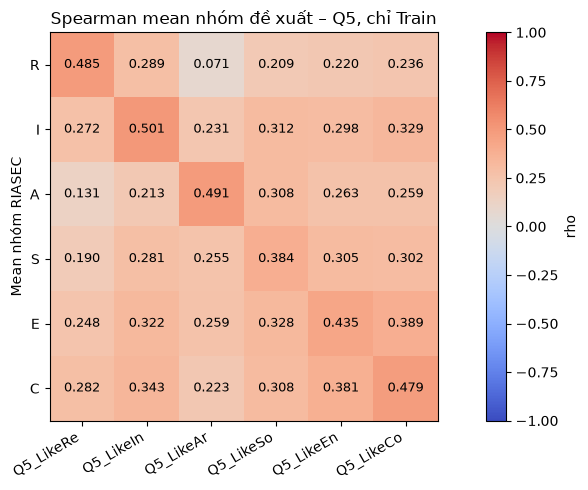

In [8]:
item_corr=X_train.corr(method='spearman')
item_pairs=pd.DataFrame([(question_columns[i],question_columns[j],item_corr.iloc[i,j]) for i in range(27) for j in range(i+1,27)],columns=['Câu 1','Câu 2','rho'])
item_pairs['|rho|']=item_pairs['rho'].abs()
item_pairs=item_pairs.sort_values('|rho|',ascending=False)
high_pairs=item_pairs.loc[item_pairs['|rho|']>=.8]
very_high_pairs=item_pairs.loc[item_pairs['|rho|']>=.9]
small_pairs=item_pairs.loc[item_pairs['|rho|']<=.1]
print('Ma trận X27:')
display(item_corr.round(3))
print('Top 10 cặp X27:')
display(item_pairs.head(10).round(4))
print('Cặp |rho| >=0,8:')
display(high_pairs.round(4))
print('Số cặp cao/rất cao/liên hệ nhỏ:',len(high_pairs),len(very_high_pairs),len(small_pairs))
cb=raw_codebook.set_index('MA_COT')
for _,row in item_pairs.head(3).iterrows():
    print(row['Câu 1'],cb.loc[row['Câu 1'],'NOI_DUNG_CODEBOOK'])
    print(row['Câu 2'],cb.loc[row['Câu 2'],'NOI_DUNG_CODEBOOK'])
group_corr=group_means.corr(method='spearman')
print('Spearman sáu mean nhóm:')
display(group_corr.round(4))
joined=group_means.add_prefix('Mean_').join(y_train)
cross_corr=joined.corr(method='spearman').loc[['Mean_'+key for key in group_questions],q5_columns]
cross_corr.index=list(group_questions)
matched_corr=pd.Series([cross_corr.loc[key,col] for key,col in zip(group_questions,q5_columns)],index=list(group_questions),name='Spearman nhóm–Q5 tương ứng')
display(matched_corr.round(4).to_frame())
display(cross_corr.round(4))
fig,ax=plt.subplots(figsize=(10,5))
im=ax.imshow(cross_corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(6),q5_columns,rotation=30,ha='right')
ax.set_yticks(range(6),list(group_questions))
for i in range(6):
    for j in range(6):ax.text(j,i,f'{cross_corr.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9)
ax.set(title='Spearman mean nhóm đề xuất – Q5, chỉ Train',ylabel='Mean nhóm RIASEC')
fig.colorbar(im,ax=ax,label='rho');plt.tight_layout();plt.show()


Nhận xét: các hệ số tương ứng và chéo cho biết liên hệ quan sát được giữa hai bộ câu hỏi; không xác nhận Q5 là nhãn nghề phù hợp hoặc hiệu năng của mô hình tương lai. Mean nhóm là phép tổng hợp cùng các câu nên tương quan này chưa độc lập với cấu trúc đo lường. Không loại biến chỉ vì tương quan cao; cần codebook và thẩm định nội dung/tâm trắc.

Trong kết quả thực tế, không có cặp X27 đạt |rho|≥0,8 hoặc ≤0,1. C3–C4 có rho=0,6712, liên hệ nội dung kiểm toán với dữ liệu/giao dịch ngân hàng; R3–R5 rho=0,6583 cùng chủ đề kỹ thuật nhưng điện tử và cơ khí là nội dung khác nhau. Chưa đủ cơ sở kết luận câu trùng. Giữa các mean nhóm, E–C cao nhất 0,7634 và R–A thấp nhất 0,4236; chưa có cặp đạt ngưỡng 0,8. Liên hệ chéo R–Q5_LikeAr nhỏ (0,0710). Các hệ số tương ứng từ S–Q5_LikeSo=0,3844 đến I–Q5_LikeIn=0,5013, và lớn hơn các hệ số chéo trong từng hàng của bảng này; đây vẫn chỉ là liên hệ mô tả, không là độ chính xác dự đoán.

## 8. Vector trùng và phản hồi ít biến thiên — chỉ Train
Giữ ngưỡng mô tả từ Notebook 01: variance ddof=0 bằng 0; hoặc 0 < variance ≤0,10. Không dùng Q5 quyết định loại mẫu. Group chỉ dùng thống kê tập trung của vector, không đưa vào X hoặc tạo nhãn.

In [9]:
response_variance=X_train.var(axis=1,ddof=0)
straightline=X_train.nunique(axis=1).eq(1)
low_nonzero=response_variance.gt(0)&response_variance.le(.1)
assert straightline.equals(response_variance.eq(0))
train_sizes=groups_train.value_counts()
duplicate_group_ids=train_sizes.index[train_sizes.gt(1)]
quality_summary=pd.Series({
    'Train n':len(X_train),'Group X27 phân biệt':groups_train.nunique(),
    'Dòng trùng thêm X27':int(X_train.duplicated().sum()),
    'Nhóm X27 trùng':len(duplicate_group_ids),'Dòng thuộc nhóm X27 trùng':int(train_sizes.loc[duplicate_group_ids].sum()),
    'Dòng variance=0':int(straightline.sum()),'Dòng 0<variance<=0,10':int(low_nonzero.sum()),
    'Dòng variance<=0,10':int(response_variance.le(.1).sum())},name='Số lượng')
display(quality_summary.to_frame())
quality_percent=pd.Series({'Variance=0 (%)':straightline.mean()*100,
    '0<variance<=0,10 (%)':low_nonzero.mean()*100,'Variance<=0,10 (%)':response_variance.le(.1).mean()*100})
display(quality_percent.round(4).to_frame('Tỷ lệ Train'))
straight_counts=X_train.loc[straightline,question_columns[0]].value_counts().reindex(range(1,6),fill_value=0)
display(pd.DataFrame({'Cùng mức':range(1,6),'Số mẫu':straight_counts.to_numpy(),'Tỷ lệ Train (%)':straight_counts.to_numpy()/len(X_train)*100}).round(4))
print('Phân bố kích thước nhóm trùng:')
display(train_sizes.loc[duplicate_group_ids].value_counts().sort_index().rename_axis('Số dòng/nhóm').rename('Số nhóm').to_frame())
largest_ids=train_sizes.index[train_sizes.eq(train_sizes.max())]
assert train_sizes.max()==188 and len(largest_ids)==1
largest_mask=groups_train.eq(largest_ids[0])
assert largest_mask.sum()==188
assert X_train.loc[largest_mask].drop_duplicates().shape[0]==1
largest_common_level=X_train.loc[largest_mask].nunique(axis=1).eq(1).all()
print('Nhóm lớn nhất: 188 dòng, chiếm',largest_mask.mean()*100,'% Train.')
print('Các dòng trong nhóm 188 đều trả lời cùng mức cho cả 27 câu:',bool(largest_common_level))
print('Mức chung (thống kê của nhóm, không hiển thị vector/định danh):',X_train.loc[largest_mask,question_columns[0]].unique().tolist())
print('Tỷ trọng nhóm 188 trong các dòng variance=0 (%):',188/straightline.sum()*100)
# Đây là mô tả kết quả riêng Q5 của nhóm Train, không dùng để lọc.
print('Số mức Q5 phân biệt trong nhóm 188:')
display(y_train.loc[largest_mask].nunique().rename('Số mức').to_frame())


Phân bố kích thước nhóm trùng:
Nhóm lớn nhất: 188 dòng, chiếm 4.743880898309362 % Train.
Các dòng trong nhóm 188 đều trả lời cùng mức cho cả 27 câu: True
Mức chung (thống kê của nhóm, không hiển thị vector/định danh): [3]
Tỷ trọng nhóm 188 trong các dòng variance=0 (%): 60.84142394822006
Số mức Q5 phân biệt trong nhóm 188:


                           Số lượng
Train n                        3963
Group X27 phân biệt            3568
Dòng trùng thêm X27             395
Nhóm X27 trùng                   45
Dòng thuộc nhóm X27 trùng       440
Dòng variance=0                 309
Dòng 0<variance<=0,10           193
Dòng variance<=0,10             502

                      Tỷ lệ Train
Variance=0 (%)             7.7971
0<variance<=0,10 (%)       4.8700
Variance<=0,10 (%)        12.6672

   Cùng mức  Số mẫu  Tỷ lệ Train (%)
0         1      41           1.0346
1         2       0           0.0000
2         3     188           4.7439
3         4      56           1.4131
4         5      24           0.6056

              Số nhóm
Số dòng/nhóm         
2                  23
3                   8
4                   2
5                   5
7                   2
14                  1
24                  1
41                  1
56                  1
188                 1

           Số mức
Q5_LikeRe       5
Q5_LikeIn       5
Q5_LikeAr       5
Q5_LikeSo       5
Q5_LikeEn       5
Q5_LikeCo       5

Nhận xét: mỗi vector lặp được tính theo số người trong thống kê gộp, nên nhóm 188 có trọng số 188 dòng và tạo tập trung ở mức 3. Giữ group giúp tránh vector trùng giao ranh giới dữ liệu, nhưng không xóa ảnh hưởng trọng số lên mô tả. Không thể kết luận gian lận hoặc sai nhãn từ trùng/ít biến thiên. Không loại dòng nào hoặc tính lại kết quả sau loại mẫu.

In [10]:
assert X_train.shape==(3963,27) and y_train.shape==(3963,6)
assert groups_train.nunique()==3568
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert X_train.index.equals(y_train.index) and X_train.index.equals(groups_train.index)
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()==train_index_sha256
assert 'X_test' not in globals() and 'y_test' not in globals()
assert 'raw_survey' not in globals() and 'survey_int' not in globals()
assert X_train.notna().all().all() and y_train.notna().all().all()
sha_after=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert sha_before==sha_after
print('PASS: EDA chỉ trên Train; không đổi index/dòng/cột, workbook không đổi.')
print('SHA-256 workbook:',sha_after)


PASS: EDA chỉ trên Train; không đổi index/dòng/cột, workbook không đổi.
SHA-256 workbook: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


## 9. Kết luận và lưu ý Notebook 04
Không có bước tự động xóa câu/mẫu trong EDA. Những mô tả này chưa là bằng chứng đủ để loại biến khoa học hoặc chọn mô hình. Khi chuẩn hóa sau này, chỉ fit trên Train; khi CV, scaler và mọi feature selection học tham số phải nằm trong Pipeline của từng training fold, giữ ranh giới group. Không tái sử dụng phép biến đổi fit toàn Train cho CV. Likert cùng thang không mặc nhiên đòi hỏi scaling; tác động còn phụ thuộc thuật toán.

Q5 cần baseline và chỉ số riêng từng đầu ra, lưu ý mất cân bằng và thứ bậc; không gộp thành nhãn argmax hoặc ngành học. Tương quan, overlap và phản hồi cùng mức chỉ là mô tả trong mẫu, không suy luận quan hệ nhân quả, độ chính xác dự đoán hay phần trăm phù hợp nghề.

Kiểm chứng: thực thi tuần tự các code cell trong tiến trình Python 3.14 mới. Bốn biểu đồ và bảng nhúng trực tiếp, không xuất file phụ. Dùng phương án được cho phép theo lỗi quyền Jupyter Windows đã ghi nhận; chưa xác nhận thực thi qua giao diện/kernel Jupyter. Test chỉ dùng kiểm tra tái lập ranh giới trước EDA; đã bỏ các tham chiếu dữ liệu Test/toàn tập. Không sửa workbook, notebook cũ, website hoặc pipeline F54. Dừng ở Notebook 03, không tạo Notebook 04.


### Kết quả thực tế và trả lời câu hỏi nghiên cứu
- **10/10 code cell**, bốn biểu đồ; Train **3.963 × 27**, y_train **3.963 × 6**, **3.568 group**. Chữ ký index Train/Test khớp Notebook 02; Test chỉ được kiểm tra ranh giới trước EDA, không dùng phân tích/ra quyết định.
- SD 27 câu từ **1.0146 đến 1.2210**; **0** câu SD <0,5; **0** câu có một mức ≥80%. Không có bằng chứng theo các ngưỡng mô tả này rằng câu nào gần như không thay đổi; đây không là kiểm định giá trị khoa học.
- Mean nhóm mô tả: R=2.4907, I=2.6955, A=2.7012, S=2.8379, E=2.7594, C=2.5308. Nhóm S có mean cao nhất, R thấp nhất; overlap theo bins thể hiện mức chồng lấn, chưa kết luận khác biệt tâm lý có ý nghĩa hoặc khả năng phân loại.
- Mức **3** phổ biến nhất ở cả sáu Q5; tỷ số max/min số mẫu theo Q5 từ **1.58 đến 2.92**. Cần baseline từng đầu ra và chỉ số theo lớp/thứ bậc ở bước sau, không coi năm mức cân bằng. Có **2173 mẫu (54.8322%)** đồng hạng cao nhất; không tạo nhãn argmax hoặc loại các dòng này.
- Spearman X27 có **0** cặp |rho|≥0,8 và **0** cặp ≥0,9. Cặp mạnh nhất **C3–C4**, rho=**0.6712**. Xem nội dung thực tế trước khi bàn dư thừa; chưa có căn cứ để loại bất kỳ câu nào ngay lúc này.
- Spearman nhóm–Q5 tương ứng: R=0.4850, I=0.5013, A=0.4905, S=0.3844, E=0.4351, C=0.4792. Có liên hệ quan sát được, chưa chứng minh nhân quả, tính độc lập của nhãn, hiệu năng mô hình tương lai hoặc giá trị nghề nghiệp.
- Train có **309** dòng variance=0, **193** dòng ít biến thiên khác 0, tổng **502** dòng variance≤0,10. Không dùng Q5 để lọc; chưa loại dòng nào.
- **395** dòng trùng thêm, **45** nhóm trùng với **440** dòng. Nhóm **188** cùng trả lời mức 3 chiếm **4.7439% Train**, tạo tập trung ở mức 3 cho mọi câu/mean nhóm. Thống kê có trọng số theo số dòng, chưa tách được phản hồi độc lập và xu hướng trả lời chung; không quy kết gian lận.
- Notebook 04: cùng thang 1–5 không có nghĩa scaling chắc chắn hữu ích; chỉ fit trên Train, trong CV phải fit lại trong Pipeline từng fold. Cân nhắc thứ bậc, tương quan, nhóm lặp và mất cân bằng Q5, chưa tự chọn/bỏ biến. Mean nhóm chỉ là tổng hợp mô tả chưa xác minh chính thức.
- Workbook SHA-256 giữ nguyên **c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8**. Đã kiểm tra hash các notebook cũ/pipeline F54, hai workbook và source website/kiểm thử không thay đổi. Chưa kiểm chứng bằng giao diện/kernel Jupyter; dừng sau Notebook 03.
